# Ejercicio 2 — Descenso de gradiente matricial
Se desarrollan los cinco puntos del ejercicio con cálculo analítico y comprobación computacional.

$$f(x)=\frac12 x^TAx-b^Tx,\quad A=\begin{pmatrix}1&0&0\\0&3&0\\0&0&5\end{pmatrix},\quad b=\begin{pmatrix}-3\\6\\-10\end{pmatrix}$$
$$\gamma=0.25,\qquad x^{(0)}=(1,0,1)^T$$
Se utiliza el gradiente como vector columna, equivalente a transponer el gradiente fila del enunciado.

In [1]:
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
x1, x2, x3 = sp.symbols('x_1 x_2 x_3', real=True)
x = sp.Matrix([x1,x2,x3])
A = sp.diag(1,3,5)
b = sp.Matrix([-3,6,-10])

## 1. Desarrollo del producto matricial
$$Ax=(x_1,3x_2,5x_3)^T$$
$$x^TAx=x_1^2+3x_2^2+5x_3^2,\qquad b^Tx=-3x_1+6x_2-10x_3$$
Por tanto:
$$f(x)=\frac12x_1^2+\frac32x_2^2+\frac52x_3^2+3x_1-6x_2+10x_3$$

In [2]:
display(A*x, (x.T*A*x)[0], (b.T*x)[0])
f = sp.expand((sp.Rational(1,2)*x.T*A*x-b.T*x)[0])
display(f)

Matrix([
[  x_1],
[3*x_2],
[5*x_3]])

x_1**2 + 3*x_2**2 + 5*x_3**2

-3*x_1 + 6*x_2 - 10*x_3

x_1**2/2 + 3*x_1 + 3*x_2**2/2 - 6*x_2 + 5*x_3**2/2 + 10*x_3

## 2. Gradiente matricial y derivadas parciales
Dado que $A=A^T$, el gradiente columna es $Ax-b$.
$$\nabla f=\begin{pmatrix}x_1+3\\3x_2-6\\5x_3+10\end{pmatrix}$$
Analíticamente, $\partial f/\partial x_1=x_1+3$, $\partial f/\partial x_2=3x_2-6$ y $\partial f/\partial x_3=5x_3+10$.

In [3]:
g = A*x-b
g_parcial = sp.Matrix([sp.diff(f,v) for v in x])
display(g, g_parcial)
assert g == g_parcial
print('Ambos gradientes coinciden.')

Matrix([
[   x_1 + 3],
[ 3*x_2 - 6],
[5*x_3 + 10]])

Matrix([
[   x_1 + 3],
[ 3*x_2 - 6],
[5*x_3 + 10]])

Ambos gradientes coinciden.


## 3. Puntos críticos
Igualando las componentes a cero:
$$x_1+3=0\Rightarrow x_1=-3$$
$$3x_2-6=0\Rightarrow x_2=2$$
$$5x_3+10=0\Rightarrow x_3=-2$$
El único punto crítico es $x^*=(-3,2,-2)^T$.

In [4]:
sol = sp.solve(list(g), list(x))
optimo = x.subs(sol)
display(sol, optimo, g.subs(sol))

{x_1: -3, x_2: 2, x_3: -2}

Matrix([
[-3],
[ 2],
[-2]])

Matrix([
[0],
[0],
[0]])

## 4. Segundas derivadas y clasificación
Las segundas derivadas puras son 1, 3 y 5. Las seis derivadas cruzadas son cero.
$$H=\begin{pmatrix}1&0&0\\0&3&0\\0&0&5\end{pmatrix}$$
Los menores principales líderes son $D_1=1$, $D_2=3$ y $D_3=15$. Por el criterio de Sylvester, la Hessiana es definida positiva en todo el dominio. El punto crítico es un mínimo estricto global, no un máximo ni un punto silla.
$$f(-3,2,-2)=4.5+6+10-9-12-20=-20.5$$

In [5]:
H = sp.hessian(f, list(x))
display(H)
for i in range(3):
    for j in range(3):
        if i != j:
            print(f'Derivada cruzada ({i+1},{j+1}): {H[i,j]}')
            assert H[i,j] == 0
menores = [H[:k,:k].det() for k in range(1,4)]
print('Menores principales:', menores)
assert all(d > 0 for d in menores)
print('Mínimo global:', f.subs(sol))

Matrix([
[1, 0, 0],
[0, 3, 0],
[0, 0, 5]])

Derivada cruzada (1,2): 0
Derivada cruzada (1,3): 0
Derivada cruzada (2,1): 0
Derivada cruzada (2,3): 0
Derivada cruzada (3,1): 0
Derivada cruzada (3,2): 0
Menores principales: [1, 3, 15]
Mínimo global: -41/2


## 5. Descenso de gradiente
$$x^{(i+1)}=x^{(i)}-0.25\nabla f(x^{(i)})$$
**Iteración 1:**
$$(1,0,1)^T-0.25(4,-6,15)^T=(0,1.5,-2.75)^T$$
**Iteración 2:**
$$(0,1.5,-2.75)^T-0.25(3,-1.5,-3.75)^T=(-0.75,1.875,-1.8125)^T$$
**Iteración 3:**
$$(-0.75,1.875,-1.8125)^T-0.25(2.25,-0.375,0.9375)^T=(-1.3125,1.96875,-2.046875)^T$$

In [6]:
An = np.array(A, dtype=float)
bn = np.array(b, dtype=float)
actual = np.array([[1.],[0.],[1.]])
gamma = 0.25
filas = []
for i in range(4):
    grad = An @ actual - bn
    valor = (0.5 * actual.T @ An @ actual - bn.T @ actual).item()
    filas.append({'Iteración': i, 'x(i)': tuple(actual.ravel().tolist()),
                  'Gradiente': tuple(grad.ravel().tolist()), 'f(x(i))': valor})
    if i < 3:
        siguiente = actual - gamma * grad
        print(f'x({i+1}) = {actual.ravel()} - {gamma} * {grad.ravel()} = {siguiente.ravel()}')
        actual = siguiente
tabla = pd.DataFrame(filas)
display(tabla)
assert np.all(np.diff(tabla['f(x(i))']) < 0)

x(1) = [1. 0. 1.] - 0.25 * [ 4. -6. 15.] = [ 0.    1.5  -2.75]
x(2) = [ 0.    1.5  -2.75] - 0.25 * [ 3.   -1.5  -3.75] = [-0.75    1.875  -1.8125]
x(3) = [-0.75    1.875  -1.8125] - 0.25 * [ 2.25   -0.375   0.9375] = [-1.3125    1.96875  -2.046875]


,Iteración,x(i),Gradiente,f(x(i))
0,0,"(1.0, 0.0, 1.0)","(4.0, -6.0, 15.0)",16.000000
1,1,"(0.0, 1.5, -2.75)","(3.0, -1.5, -3.75)",-14.218750
2,2,"(-0.75, 1.875, -1.8125)","(2.25, -0.375, 0.9375)",-17.857422
3,3,"(-1.3125, 1.96875, -2.046875)","(1.6875, -0.09375, -0.234375)",-19.069214


### Gráfica de convergencia

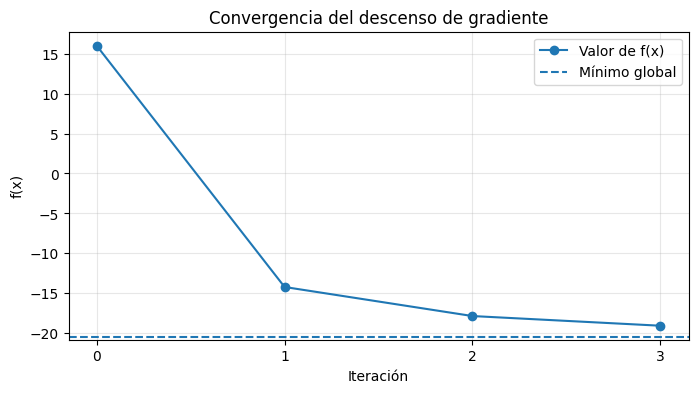

In [7]:
plt.figure(figsize=(8,4))
plt.plot(tabla['Iteración'], tabla['f(x(i))'], marker='o', label='Valor de f(x)')
plt.axhline(float(f.subs(sol)), linestyle='--', label='Mínimo global')
plt.xticks(range(4))
plt.xlabel('Iteración')
plt.ylabel('f(x)')
plt.title('Convergencia del descenso de gradiente')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Conclusión
Con una tasa de aprendizaje de 0.25, la función disminuye de 16 a -19.0692138671875 en tres iteraciones y se aproxima al mínimo global de -20.5 en (-3, 2, -2). La Hessiana definida positiva garantiza la unicidad del mínimo. La gráfica es un complemento de la tabla solicitada.